# CelebA Paper Figures: Hair Colour Along the DR Riesz Flow, Both Arms

Produces the qualitative trajectory figures (selected particles decoded at flow
snapshots) at the simulation's full scale, following the simulation script's exact
seed path — `data_seed = 0`, `repeat = 0`, the same split/nuisance/particle-pick/flow
seeds — so the run shown here is the same run (up to CUDA nondeterminism) as the
$(n_{\mathrm{obs}}, \mathrm{seed}\,0)$ rows of
`Simulations/CelebA/dr_mmd_flow/results/`.

**Workflow**: (1) run with `N_OBS` set below; (2) eyeball the candidate grids in
Section 4 (start/end pairs, ranked by pixel change, with indices); (3) put the chosen
indices into `FEMALE_TRACK` / `MALE_TRACK` in Section 5 and re-run that cell — the
figure PDFs land in `figures/`. Particle indices are specific to `(N_OBS, seed)`: a
particle number chosen at one size names a different face at another, so selection
must happen at the size the paper figure uses.

In [1]:
import sys
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

sys.path.append("../../src")
torch.set_default_dtype(torch.float32)

from data_utils import load_celeba_paper
from data_utils.celeba import to_image_range
from autoencoder_utils import decode_latents, encode_images, load_sd_vae
from causality_utils import (cpme_dr_weights_crossfit, make_crossfit_fold_ids,
                             select_regularization)
from dens_ratio_utils import crossfit_propensity
from mmd_flow_utils import adamw_riesz_flow

SEED = 0          # = the simulation's pipeline seed for (data_seed 0, repeat 0)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda


In [2]:
N_OBS = 20000        # full scale; drop to 16384 (cached) or 2048 for quick iteration
N_REF, IMAGE_SIZE = 2000, 256
CELEBA_ROOT = "/nfs/ghome/live/danceh/data/celeba"
REPO_CACHE = Path("../../data/celeba_dgp")
LOCAL_CACHE = Path("/tmp/celeba_dgp_local")   # big generated caches go to LOCAL disk,
LOCAL_CACHE.mkdir(exist_ok=True)              # never to the NFS home quota

name = f"celeba_paper_{IMAGE_SIZE}_n{N_OBS}_nref{N_REF}_seed0.pt"
cache = next((c for c in (REPO_CACHE / name, LOCAL_CACHE / name) if c.exists()),
             LOCAL_CACHE / name)
data = load_celeba_paper(cache, root=CELEBA_ROOT, seed=0, image_size=IMAGE_SIZE,
                         n_obs=N_OBS, n_ref=N_REF, verbose=False)
A = data["A"].view(-1).long()
X = data["X"].view(-1).long()
Y = data["Y"]
del data                                       # keep only what the figures need
print(f"n = {N_OBS}   arm sizes: female {int((A == 0).sum())}, male {int((A == 1).sum())}")

n = 20000   arm sizes: female 11000, male 9000


In [3]:
vae = load_sd_vae(device)
Z = encode_images(vae, Y)
latent_mean = Z.mean(dim=0, keepdim=True)
latent_std = Z.std(dim=0, keepdim=True).clamp_min(1e-3)
Z_std = (Z - latent_mean) / latent_std
from_flow = lambda p: p * latent_std + latent_mean
print("latents:", tuple(Z.shape))

/nfs/ghome/live/bbozkurt/.conda/envs/torchnn/lib/python3.12/site-packages/huggingface_hub/utils/_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


latents: (20000, 4096)


In [4]:
# Cross-fitted nuisances and per-arm flows, mirroring the simulation line for line
# (DR support capped at 4096 rows, subsampled with seed SEED+5 when N_OBS exceeds it).
N_DR = 4096
if N_DR < N_OBS:
    pick_dr = torch.randperm(N_OBS, generator=torch.Generator().manual_seed(SEED + 5))[:N_DR]
else:
    pick_dr = torch.arange(N_OBS)
A_s, X_s, Z_std_s = A[pick_dr], X[pick_dr], Z_std[pick_dr]
n_dr = len(pick_dr)

fold_ids = make_crossfit_fold_ids(n_dr, n_folds=5, seed=0)
torch.manual_seed(SEED)
e1 = crossfit_propensity(X_s.double().unsqueeze(1), A_s.double(), fold_ids)

K_pair = ((X_s[:, None] == X_s[None, :]) & (A_s[:, None] == A_s[None, :])).double()
fold_lambdas = {}
for fold in np.unique(fold_ids):
    train = np.where(fold_ids != fold)[0]
    fold_lambdas[int(fold)], _ = select_regularization(K_pair[train][:, train],
                                                       Z_std_s[train, 0].double().cpu(),
                                                       seed=0)

flows = {}
for arm in (0, 1):
    w_hat = (A_s == arm).double() / (e1 if arm == 1 else 1.0 - e1)
    K_x = (X_s[:, None] == X_s[None, :]).double()
    K_a = (A_s[:, None] == A_s[None, :]).double()
    K_a_target = (A_s == arm).double()[:, None].expand(n_dr, n_dr).contiguous()
    v_dr = cpme_dr_weights_crossfit(K_x, K_a, K_a_target, w_hat, fold_ids,
                                    fold_lambdas).float().to(device)

    arm_indices = torch.nonzero(A == arm).ravel()
    M = min(1024, len(arm_indices))
    pick = arm_indices[torch.randperm(len(arm_indices),
                                      generator=torch.Generator().manual_seed(SEED))[:M]]
    initial = Z_std[pick].clone()
    torch.manual_seed(SEED + 1)
    particles, history = adamw_riesz_flow(
        initial.clone(), Z_std_s, target_weights=v_dr, sliced=False,
        n_iterations=4000, learning_rate=0.001, warmup_steps=100,
        lr_schedule="cosine", snapshot_every=200, log_every=1000, verbose=False)
    flows[arm] = {"initial": initial, "particles": particles,
                  "snapshots": dict(sorted(history["snapshots"].items()))}
    flows[arm]["snapshots"][4000] = particles
    print(f"arm {arm}: M = {M}   loss {history['loss'][0]:.4f} -> {history['loss'][-1]:.4f}   "
          f"mean transport {(particles - initial).norm(dim=1).mean():.2f}")

arm 0: M = 1024   loss 63.6042 -> 63.5060   mean transport 20.40


arm 1: M = 1024   loss 64.6414 -> 64.4783   mean transport 24.67


## 4. Candidate Selection

Start/end pairs for each arm: the top 24 particles by pixel-space change (the most
visible edits — indices printed above each pair) followed by 24 random particles for
an unranked view. Pick figure particles from these indices.

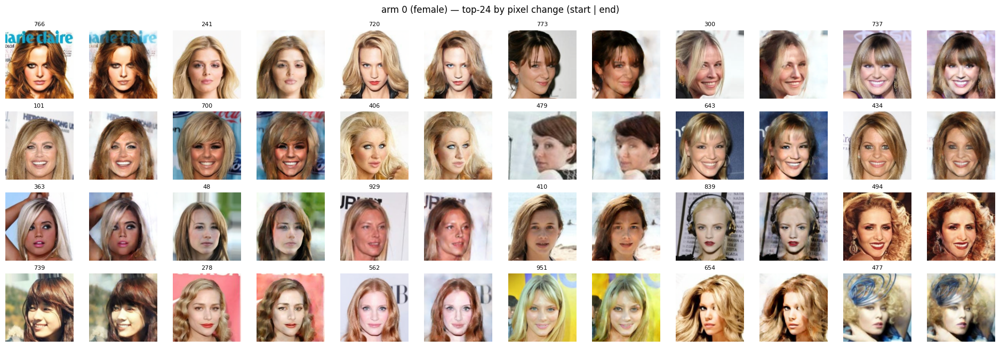

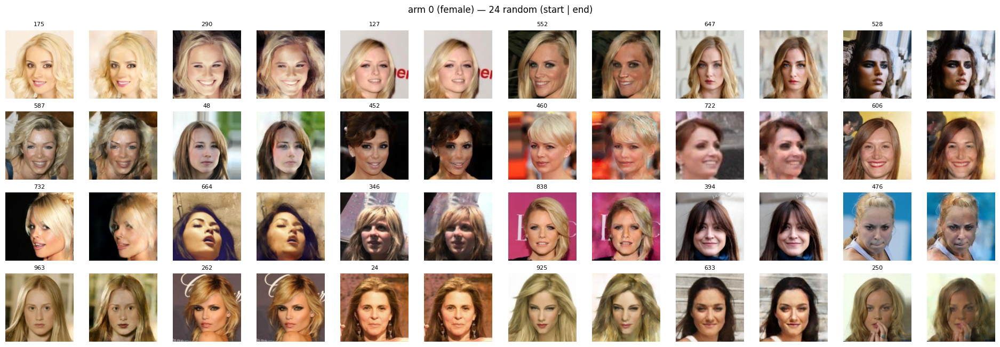

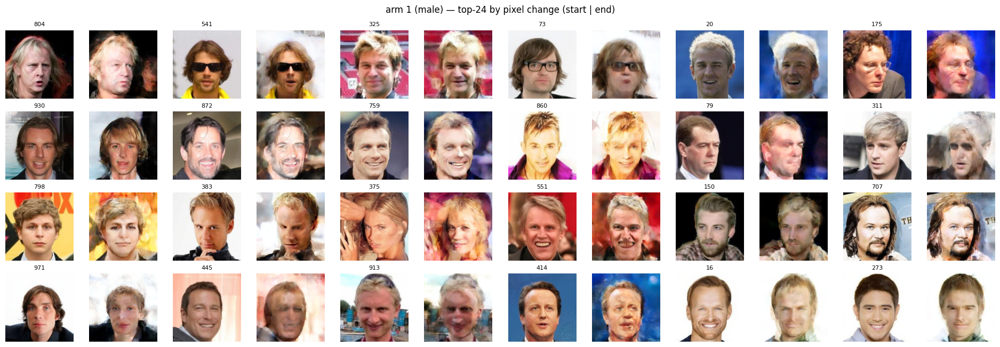

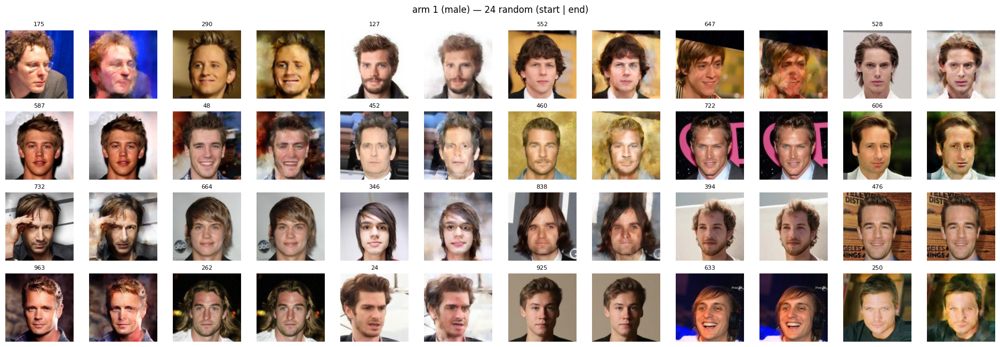

In [5]:
@torch.no_grad()
def decode_all(latents, chunk=64):
    return torch.cat([decode_latents(vae, from_flow(latents[i:i + chunk]), IMAGE_SIZE)
                      for i in range(0, len(latents), chunk)])


decoded = {}
for arm in (0, 1):
    start = decode_all(flows[arm]["initial"])
    end = decode_all(flows[arm]["particles"])
    change = (end - start).flatten(1).norm(dim=1)
    decoded[arm] = {"start": start, "end": end, "change": change}

for arm, arm_name in ((0, "female"), (1, "male")):
    change = decoded[arm]["change"]
    top = torch.argsort(change, descending=True)[:24]
    rng = torch.randperm(len(change), generator=torch.Generator().manual_seed(7))[:24]
    for label, indices in (("top-24 by pixel change", top), ("24 random", rng)):
        fig, axes = plt.subplots(4, 12, figsize=(19, 6.6))
        for k, index in enumerate(indices):
            row, col = divmod(k, 6)
            for j, stage in enumerate(("start", "end")):
                ax = axes[row, 2 * col + j]
                ax.imshow(to_image_range(decoded[arm][stage][index]).permute(1, 2, 0).numpy())
                ax.axis("off")
                if j == 0:
                    ax.set_title(f"{int(index)}", fontsize=8)
        fig.suptitle(f"arm {arm} ({arm_name}) — {label} (start | end)", fontsize=12)
        fig.tight_layout()
        plt.show()

## 5. The Paper Figure

Set the chosen particle indices below (from Section 4) and re-run. One PDF per arm
lands in `figures/`.

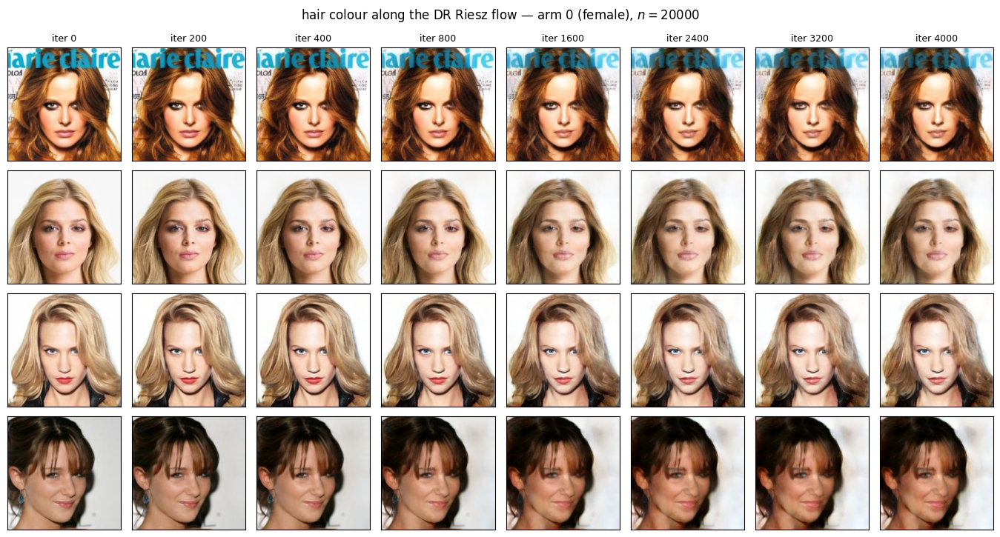

arm 0: tracked particles [766, 241, 720, 773] -> figures/celeba_hair_flow_female_n20000.pdf


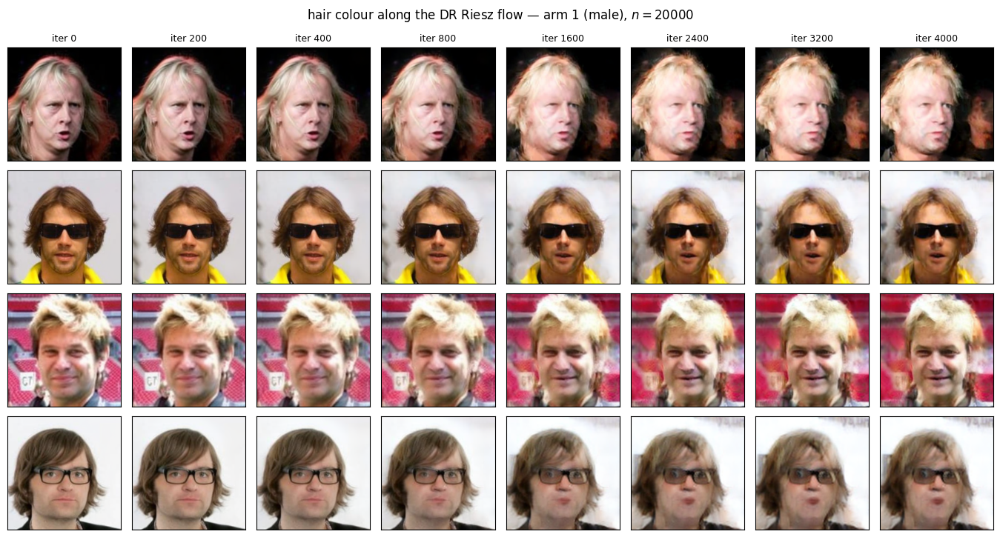

arm 1: tracked particles [804, 541, 325, 73] -> figures/celeba_hair_flow_male_n20000.pdf


In [6]:
FEMALE_TRACK = None   # e.g. [12, 847, 301, 55]; None -> top-4 by pixel change
MALE_TRACK = None
SHOWN_STEPS = [0, 200, 400, 800, 1600, 2400, 3200, 4000]
Path("figures").mkdir(exist_ok=True)

for arm, arm_name, track in ((0, "female", FEMALE_TRACK), (1, "male", MALE_TRACK)):
    if track is None:
        track = torch.argsort(decoded[arm]["change"], descending=True)[:4].tolist()
    snapshots = flows[arm]["snapshots"]
    with torch.no_grad():
        frames = {step: decode_latents(vae, from_flow(snapshots[step][track]), IMAGE_SIZE)
                  for step in SHOWN_STEPS}
    fig, axes = plt.subplots(len(track), len(SHOWN_STEPS),
                             figsize=(1.7 * len(SHOWN_STEPS), 1.85 * len(track)))
    for row, particle in enumerate(track):
        for col, step in enumerate(SHOWN_STEPS):
            axes[row, col].imshow(to_image_range(frames[step][row]).permute(1, 2, 0).numpy())
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
            if row == 0:
                axes[row, col].set_title(f"iter {step}", fontsize=9)
    fig.suptitle(f"hair colour along the DR Riesz flow — arm {arm} ({arm_name}), "
                 f"$n = {N_OBS}$", fontsize=12)
    fig.tight_layout()
    for ext in ("pdf", "png"):
        fig.savefig(f"figures/celeba_hair_flow_{arm_name}_n{N_OBS}.{ext}",
                    dpi=200, bbox_inches="tight")
    plt.show()
    print(f"arm {arm}: tracked particles {track} -> "
          f"figures/celeba_hair_flow_{arm_name}_n{N_OBS}.pdf")